# Maryland UMD Cyber Events Dataset – Incidents by Target Sector (Test Notebook)
This test notebook loads the University of Maryland (UMD) Cyber Events Database (`umd_cyber_events.xlsx`), normalizes target sector labels (`industry` / harmonized sectors), and visualizes incident counts and shares by target sector both **globally** and **for Germany**.

In [1]:
# Import core data processing and visualization libraries
import pathlib
import sys
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress non-critical warnings for clean notebook output
warnings.filterwarnings("ignore")

# Configure publication-grade visual theme
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

# Resolve paths relative to current working directory so notebook works from root or germany/notebooks
CWD = pathlib.Path.cwd()
if CWD.name == "notebooks":
    GERMANY_DIR = CWD.parent
elif (CWD / "germany").exists():
    GERMANY_DIR = CWD / "germany"
else:
    GERMANY_DIR = CWD

# Add scripts directory to path so we can also use project harmonization helpers
sys.path.insert(0, str(GERMANY_DIR / "scripts"))
from harmonize_helpers import resolve_umd_sector

UMD_PATH = GERMANY_DIR / "data" / "raw" / "umd_cyber_events.xlsx"
df_umd = pd.read_excel(UMD_PATH)

# Normalize inconsistent capitalization in raw UMD NAICS industry labels
# (e.g., "Finance And Insurance" / "Finance and insurance" -> "Finance and Insurance")
CASE_NORMALIZATION_MAP = {
    "Finance And Insurance": "Finance and Insurance",
    "Finance and insurance": "Finance and Insurance",
    "Health Care And Social Assistance": "Health Care and Social Assistance",
    "Educational services": "Educational Services",
}
df_umd["target_sector_raw"] = (
    df_umd["industry"]
    .fillna("Undetermined")
    .astype(str)
    .str.strip()
    .replace(CASE_NORMALIZATION_MAP)
)

# Also compute the project-harmonized 10-sector taxonomy for direct comparison
df_umd["target_sector_harmonized"] = [
    resolve_umd_sector(ind, org, desc)
    for ind, org, desc in zip(
        df_umd["industry"], df_umd["organization"], df_umd["description"]
    )
]

# Filter subset for German targets
df_umd_de = df_umd[
    (df_umd["country"] == "Germany") | (df_umd["country_iso3"] == "DEU")
].copy()

print(f"Total UMD Cyber Events (Global):  {len(df_umd):,} incidents")
print(f"Total UMD Cyber Events (Germany): {len(df_umd_de):,} incidents")

Total UMD Cyber Events (Global):  17,016 incidents
Total UMD Cyber Events (Germany): 291 incidents


## 2. Germany Subset: Raw UMD NAICS Sectors vs. Harmonized Target Sectors
For German targets in the UMD dataset, we compare the raw NAICS `industry` classification (left) with the project's harmonized 10-sector taxonomy (right).

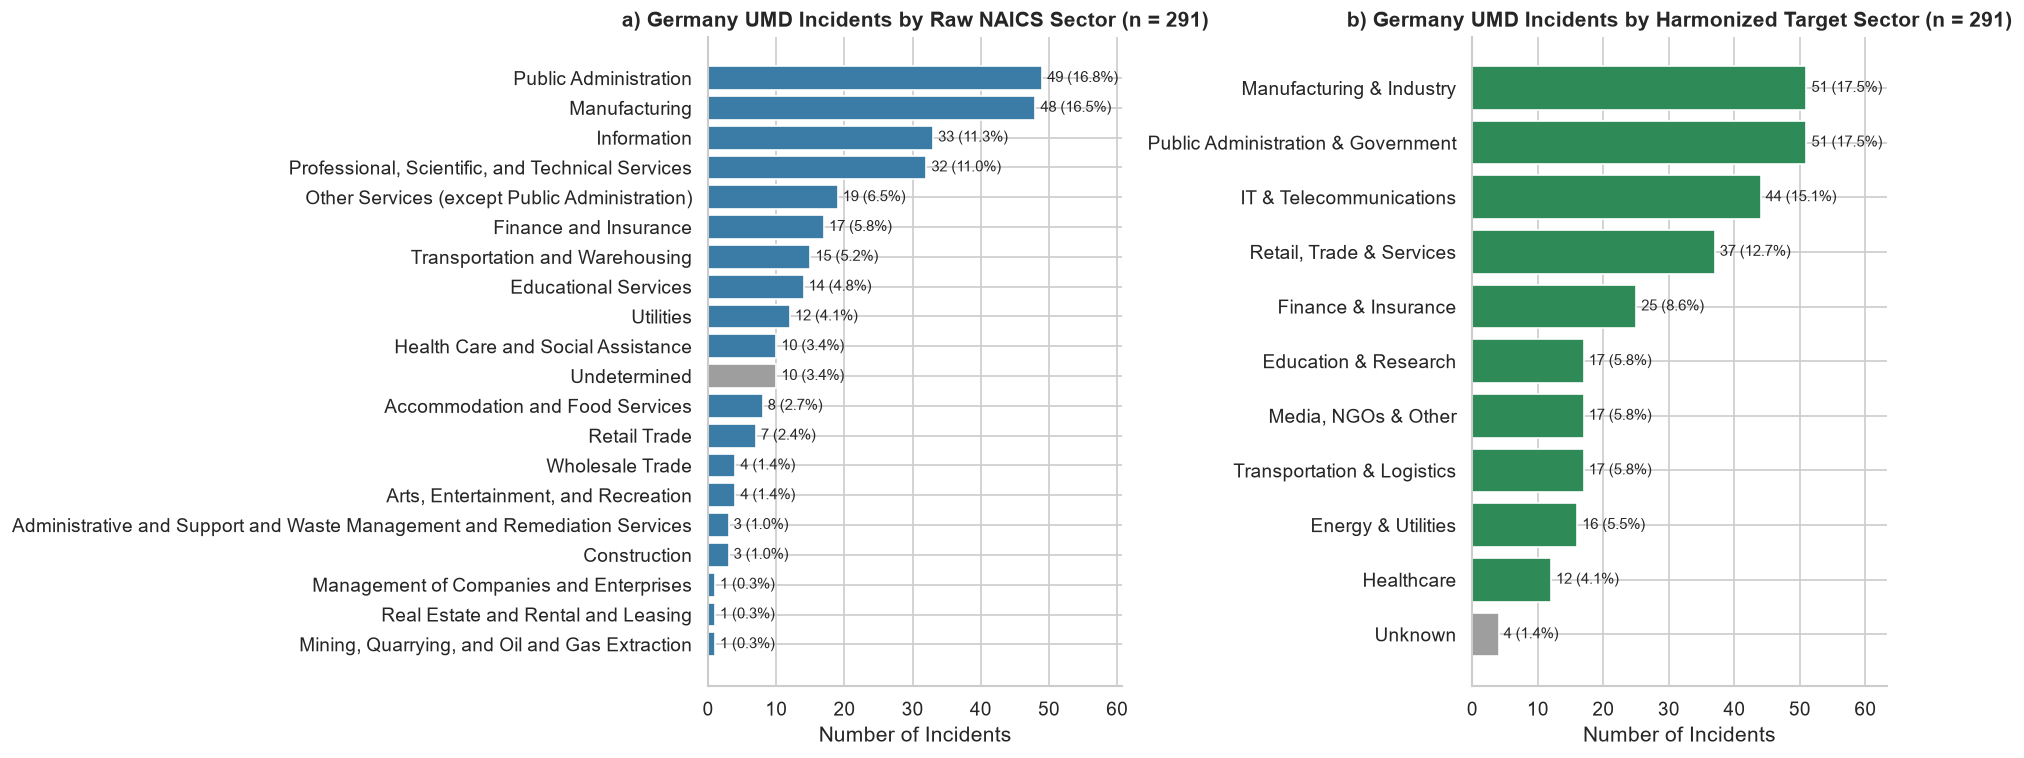

In [3]:
# Aggregate German UMD incidents by raw NAICS industry and by harmonized target sector
de_raw_counts = (
    df_umd_de["target_sector_raw"]
    .value_counts()
    .rename_axis("target_sector")
    .reset_index(name="incidents")
    .sort_values("incidents", ascending=True)
)
de_harm_counts = (
    df_umd_de["target_sector_harmonized"]
    .value_counts()
    .rename_axis("target_sector")
    .reset_index(name="incidents")
    .sort_values("incidents", ascending=True)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# Panel A: Raw UMD NAICS Industry (Germany)
colors_raw = [
    "#9e9e9e" if s == "Undetermined" else "#3a7ca5"
    for s in de_raw_counts["target_sector"]
]
bars1 = ax1.barh(de_raw_counts["target_sector"], de_raw_counts["incidents"], color=colors_raw)
max_raw = de_raw_counts["incidents"].max()
ax1.set_xlim(0, max_raw * 1.24)
for bar, val in zip(bars1, de_raw_counts["incidents"]):
    pct = val / len(df_umd_de) * 100
    ax1.text(
        bar.get_width() + max_raw * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val} ({pct:.1f}%)",
        va="center",
        fontsize=9,
    )
ax1.set_title(f"a) Germany UMD Incidents by Raw NAICS Sector (n = {len(df_umd_de)})")
ax1.set_xlabel("Number of Incidents")

# Panel B: Harmonized 10-Sector Taxonomy (Germany)
colors_harm = [
    "#9e9e9e" if s == "Unknown" else "#2e8b57"
    for s in de_harm_counts["target_sector"]
]
bars2 = ax2.barh(de_harm_counts["target_sector"], de_harm_counts["incidents"], color=colors_harm)
max_harm = de_harm_counts["incidents"].max()
ax2.set_xlim(0, max_harm * 1.24)
for bar, val in zip(bars2, de_harm_counts["incidents"]):
    pct = val / len(df_umd_de) * 100
    ax2.text(
        bar.get_width() + max_harm * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val} ({pct:.1f}%)",
        va="center",
        fontsize=9,
    )
ax2.set_title(f"b) Germany UMD Incidents by Harmonized Target Sector (n = {len(df_umd_de)})")
ax2.set_xlabel("Number of Incidents")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()